# Step 2 - Build the desert experiment files and compare with the originals

Changes three MATSIRO input files in the **110 T42 cells** selected in step 1 (`Code/build_desert_experiment/source_region_T42.npz`:
FRONT moisture-source region 50 %, DES excluded), and draws original vs modified for each:

| File | Change in the 110 cells |
|---|---|
| `gridx01` (primary land-cover class) | set to `LC_CLASS` = 8 (shrubs & bare ground) |
| `grlai01` (natural-vegetation LAI) | each month, area-mean `grlai01` of Mongolia's DES zone (`METHOD = "des_mean"`) - lower LAI |
| `grlai02` (crop LAI) | the same values as `grlai01` (`REF_FROM`): the DES zone has almost no crops (crop fraction about 0.08 %), so its own `grlai02` values are filled-in numbers |

The other four files (`gridx02`, `glfrc01/02`, `slidx`) are copied unchanged, so `Desert_IC_files/` is a complete set of 7 files.

**Outputs**
- `Desert_IC_files/` - the 7 `.nc` files (only if `WRITE = True`)
- `Figure/build_desert_experiment/gridx01_compare.png` - original vs modified `gridx01`, global and Asia, changed cells outlined
- `Figure/build_desert_experiment/grlai01_compare.png`, `Figure/build_desert_experiment/grlai02_compare.png` - original / modified / difference LAI for 4 months
- `Figure/build_desert_experiment/grlai_seasonal_cycle.png` - mean LAI over the 110 cells, month by month

Requires step 1 (`1_DES_source_region_to_T42.ipynb`). Replaces the former `make_experiment_files.ipynb`, `compare_gridx01_figure.ipynb`
and `modify_grlai_and_compare.ipynb`.

In [1]:
import numpy as np, xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch
import shutil, hashlib
import cartopy.crs as ccrs

from pathlib import Path
HERE = Path.cwd().resolve()        # this notebook's folder: MATSIRO6_IC_exp/Code/build_desert_experiment
BASE = HERE.parents[1]             # MATSIRO6_IC_exp
EXP  = BASE / "Desert_IC_files"   # the 7 experiment .nc files are written here
FIG  = BASE / "Figure" / HERE.name   # figures are written to Figure/<this experiment folder>/
ROOT = HERE.parents[2]             # Geography/  (contains Mongolia/ and Boundary condition/)
SRC  = ROOT / "Boundary condition" / "bc_for_Wei" / "data" / "netcdf"    # original input files
FIG.mkdir(parents=True, exist_ok=True); EXP.mkdir(exist_ok=True)
print("experiment files:", EXP)

experiment files: /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Desert_IC_files


## 0 - Settings

`LC_CLASS` is the new `gridx01` class. For LAI, `METHOD` chooses how the 110 cells are changed:

| `METHOD` | What happens in the 110 cells (each file separately) |
|---|---|
| `"none"` | nothing (modified = original) |
| `"des_mean"` | each month, LAI = area-weighted mean LAI (of the file named in `REF_FROM`) of the T42 cells that represent Mongolia's **DES zone** (>= `DES_FRAC_MIN` of the cell's area is DES); weight = cell area x DES share |
| `"class5_mean"` | each month, LAI = area-weighted mean LAI of the cells that are **already class 5 (coniferous forest) in the original `gridx01`** inside `REF_BOX` |
| `"scale"` | LAI x `FACTOR` |
| `"constant"` | LAI = `CONST` (one number, or a list of 12 monthly values) |

Cells outside the 110 are never touched.

In [2]:
LC_CLASS = 8                      # new gridx01 class in the 110 cells (8 = shrubs & bare ground)
VARS    = ["grlai01", "grlai02"]  # files to change: natural-vegetation LAI, crop LAI
METHOD  = "des_mean"                # "none" | "des_mean" | "class5_mean" | "scale" | "constant"
REF_FROM = {"grlai01": "grlai01",  # for "des_mean"/"class5_mean": which file the reference mean is taken from.
            "grlai02": "grlai01"}  # crop LAI also uses the natural-vegetation DES mean (DES has ~no crops)
DES_FRAC_MIN = 0.5                # for "des_mean": T42 cell counts as DES if >= this share of its area is DES
REF_BOX = (20, 140, 40, 75)       # lon0, lon1, lat0, lat1 (deg E / deg N) for "class5_mean"
FACTOR  = 1.5                     # for "scale"
CONST   = 2.0                     # for "constant": a number or 12 monthly values
WRITE   = True                    # True -> write the 7 files to Desert_IC_files/ (False: figures only)

## 1 - Read the originals and build the modified fields

In [3]:
sel = np.load(HERE / "source_region_T42.npz")["selected"]          # (64, 128) bool, from step 1
print("cells to modify:", int(sel.sum()))

gds = xr.open_dataset(SRC / "gridx01.nc", decode_times=False)
g0 = gds["GRIDX01"].values[0]                      # original land cover (64, 128)
g1 = g0.copy(); g1[sel] = LC_CLASS                 # modified land cover
print(f"gridx01: {int(sel.sum())} cells set to {LC_CLASS}; value actually changed in {int((g1 != g0).sum())}")
for k, v in zip(*np.unique(g0[sel & (g1 != g0)], return_counts=True)):
    print(f"  {int(k):>2} -> {LC_CLASS} : {int(v)} cells")
grid = xr.open_dataset(SRC / "grlai01.nc", decode_times=False)
lon = grid.lon.values; lat = grid.lat.values; latb = grid.lat_bnds.values
w   = np.cos(np.deg2rad(lat))[:, None] * np.ones((1, lon.size))  # area weight

# reference cells and their weights (the same for both files)
ref, wr = None, None
if METHOD == "des_mean":
    # DES zone (0.25 deg, zone_id == 1) -> share of each T42 cell's area that is DES (same mapping as step 1)
    mo_ds = xr.open_dataset(ROOT / "Mongolia" / "data" / "mongolia_overlay.nc")
    mlat = mo_ds.latitude.values; mlon = mo_ds.longitude.values % 360
    marea = mo_ds.cell_area.values.astype("float64"); des = (mo_ds.zone_id.values == 1)
    lb = np.sort(latb, axis=1)
    lat_idx = np.full(mlat.shape, -1)
    for j in range(lat.size):
        lat_idx[(mlat >= lb[j, 0]) & (mlat < lb[j, 1])] = j
    lon_idx = ((mlon + 1.40625) // 2.8125).astype(int) % lon.size
    J = np.repeat(lat_idx[:, None], mlon.size, 1); I = np.repeat(lon_idx[None, :], mlat.size, 0); ok = J >= 0
    tot = np.zeros(g0.shape); ind = np.zeros(g0.shape)
    np.add.at(tot, (J[ok], I[ok]), marea[ok]); np.add.at(ind, (J[ok & des], I[ok & des]), marea[ok & des])
    des_frac = np.where(tot > 0, ind / np.where(tot > 0, tot, 1), 0.0)
    ref = (des_frac >= DES_FRAC_MIN) & (g0 > 0)
    wr = w * des_frac
    print("DES T42 cells:", int(ref.sum()), "| original land classes:",
          {int(k): int(v) for k, v in zip(*np.unique(g0[ref], return_counts=True))})
elif METHOD == "class5_mean":
    L0, L1, B0, B1 = REF_BOX
    ref = (g0 == 5) & ~sel & (lon[None, :] >= L0) & (lon[None, :] <= L1) & (lat[:, None] >= B0) & (lat[:, None] <= B1)
    wr = w
    print("reference cells (class 5 in REF_BOX):", int(ref.sum()))

def modify(lai, ref_lai):
    """Return (modified LAI, 12 reference values or None). ref_lai: LAI the reference mean is taken from."""
    new = lai.copy(); target = None
    if METHOD == "none":
        pass
    elif METHOD in ("des_mean", "class5_mean"):
        target = (ref_lai[:, ref] * wr[ref]).sum(1) / wr[ref].sum()   # 12 monthly values
        new[:, sel] = target[:, None]
    elif METHOD == "scale":
        new[:, sel] = lai[:, sel] * FACTOR
    elif METHOD == "constant":
        new[:, sel] = np.broadcast_to(np.asarray(CONST, dtype=float).reshape(-1, 1), (12, int(sel.sum())))
    else:
        raise ValueError(METHOD)
    return new.astype(lai.dtype), target

mo = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
mean = lambda a: (a[:, sel] * w[sel]).sum(1) / w[sel].sum()
D = {}                                             # D[var] = dict(ds, lai, new, target)
read = lambda v: xr.open_dataset(SRC / f"{v}.nc", decode_times=False)
for v in VARS:
    ds = read(v)
    lai = ds[v.upper()].values                     # (12, 64, 128)
    rv = REF_FROM.get(v, v)
    new, target = modify(lai, lai if rv == v else read(rv)[rv.upper()].values)
    D[v] = dict(ds=ds, lai=lai, new=new, target=target)
    print(f"\n{v}  (METHOD = {METHOD}" + (f", reference from {rv}" if METHOD in ("des_mean", "class5_mean") else "") + ")")
    print("month  original  modified")
    for m, a, b in zip(mo, mean(lai), mean(new)):
        print(f"{m}    {a:7.2f}   {b:7.2f}")
    print("cells outside the 110 unchanged:", np.array_equal(new[:, ~sel], lai[:, ~sel], equal_nan=True))

cells to modify: 110
gridx01: 110 cells set to 8; value actually changed in 98
   4 -> 8 : 6 cells
   5 -> 8 : 17 cells
   6 -> 8 : 17 cells
   9 -> 8 : 1 cells
  10 -> 8 : 57 cells
DES T42 cells: 16 | original land classes: {8: 9, 10: 7}

grlai01  (METHOD = des_mean, reference from grlai01)
month  original  modified
Jan       0.12      0.06
Feb       0.17      0.07
Mar       0.18      0.10
Apr       0.35      0.14
May       0.82      0.20
Jun       1.63      0.28
Jul       1.86      0.38
Aug       1.53      0.38
Sep       0.83      0.26
Oct       0.40      0.14
Nov       0.27      0.09
Dec       0.13      0.08
cells outside the 110 unchanged: True

grlai02  (METHOD = des_mean, reference from grlai01)
month  original  modified
Jan       0.05      0.06
Feb       0.05      0.07
Mar       0.09      0.10
Apr       0.27      0.14
May       0.68      0.20
Jun       1.48      0.28
Jul       1.88      0.38
Aug       1.39      0.38
Sep       0.74      0.26
Oct       0.33      0.14
Nov       0.2

## 2 - Write the 7 files to `Desert_IC_files/` and check them (only if `WRITE = True`)

In [4]:
OTHERS = ["gridx02.nc", "glfrc01.y1850.nc", "glfrc02.y1850.nc", "slidx.nc"]
eq  = lambda x, y: np.array_equal(x, y, equal_nan=True)
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()

def write(ds, name, values, note):
    out = ds.copy(deep=True)
    out[name].values[...] = values.astype(ds[name].dtype)
    out[name].attrs = dict(ds[name].attrs); out.attrs = dict(ds.attrs)
    out.attrs["history"] = (f"{name} {note} in {int(sel.sum())} T42 cells (FRONT source region 50%, DES excluded); "
                            "all other cells unchanged")
    out.to_netcdf(EXP / f"{name.lower()}.nc")

if WRITE:
    write(gds, "GRIDX01", g1[None], f"set to {LC_CLASS}")
    for v in VARS:
        write(D[v]["ds"], v.upper(), D[v]["new"], f"set to reference-mean LAI (METHOD={METHOD}, from {REF_FROM.get(v, v)})")
    for f in OTHERS:
        shutil.copy(SRC / f, EXP / f)              # copied unchanged
    print("written:", sorted(p.name for p in EXP.glob("*.nc")))

    # checks
    n = xr.open_dataset(EXP / "gridx01.nc", decode_times=False)["GRIDX01"].values[0]
    print("gridx01 : 110 cells = LC_CLASS:", bool((n[sel] == LC_CLASS).all()), "| other cells = original:", eq(n[~sel], g0[~sel]))
    for v in VARS:
        n = xr.open_dataset(EXP / f"{v}.nc", decode_times=False)[v.upper()].values
        print(f"{v} : = modified field:", eq(n, D[v]["new"]), "| other cells = original:", eq(n[:, ~sel], D[v]["lai"][:, ~sel]))
    for f in OTHERS:
        print(f"{f:18s} identical to original (md5):", md5(SRC / f) == md5(EXP / f))
else:
    print("WRITE = False: Desert_IC_files/ not changed")

written: ['glfrc01.y1850.nc', 'glfrc02.y1850.nc', 'gridx01.nc', 'gridx02.nc', 'grlai01.nc', 'grlai02.nc', 'slidx.nc']
gridx01 : 110 cells = LC_CLASS: True | other cells = original: True
grlai01 : = modified field: True | other cells = original: True
grlai02 : = modified field: True | other cells = original: True
gridx02.nc         identical to original (md5): True
glfrc01.y1850.nc   identical to original (md5): True
glfrc02.y1850.nc   identical to original (md5): True
slidx.nc           identical to original (md5): True


## 3 - Figure: original vs modified `gridx01`

Global and zoomed on Asia, with the cells whose value changed outlined in red. Colour scale as in `bc_for_Wei/figures/gridx01.png` (indices 0-10).

/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

saved /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Figure/build_desert_experiment/gridx01_compare.png


/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

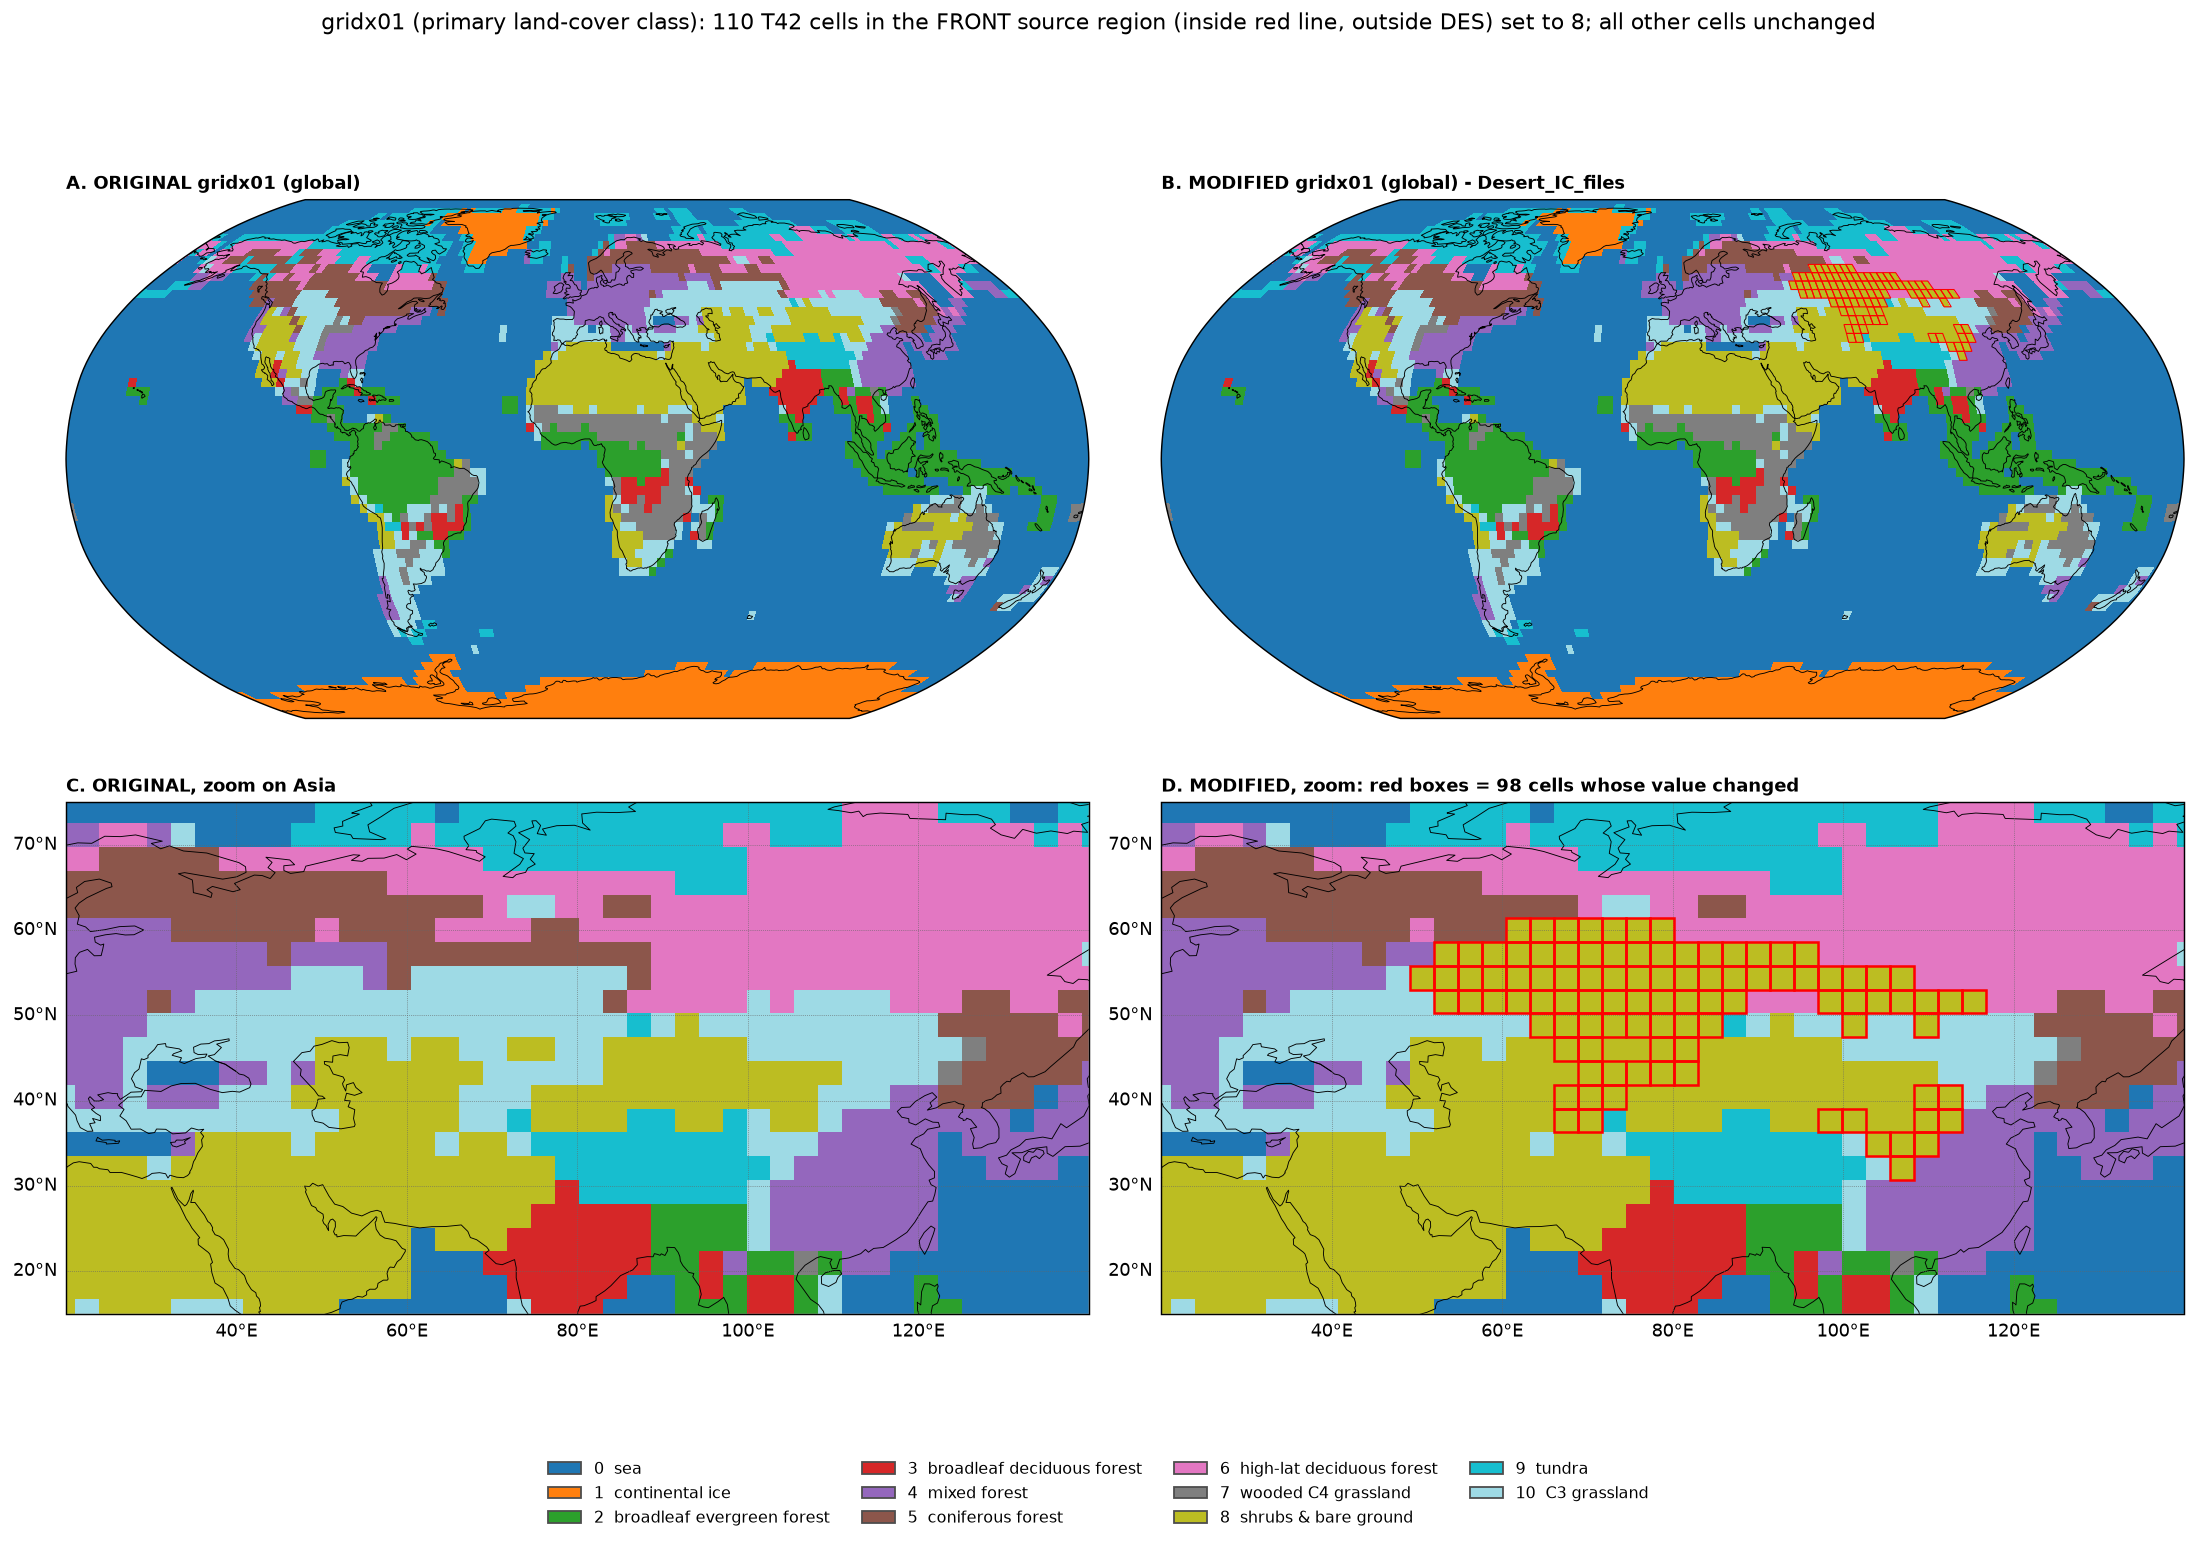

In [5]:
lon180 = np.where(lon > 180, lon - 360, lon); order = np.argsort(lon180)
xe = np.append(lon180[order] - 1.40625, lon180[order][-1] + 1.40625)
ye = np.append(latb[:, 0], latb[-1, 1])
R  = lambda a: a[..., order]
pc = ccrs.PlateCarree()
ext = (20, 140, 15, 75)                            # Asia zoom

def boxes(ax, mask, color, lw):
    for j, i in zip(*np.where(mask)):
        ax.add_patch(Rectangle((lon180[i] - 1.40625, latb[j, 1]), 2.8125, latb[j, 0] - latb[j, 1],
                               fill=False, ec=color, lw=lw, transform=pc, zorder=5))

def decorate(ax, title, zoom=True):
    try:
        ax.coastlines(lw=0.5)
    except Exception as e:
        print("no coastlines:", type(e).__name__)
    if zoom:
        ax.set_extent(ext, crs=pc)
        gl = ax.gridlines(draw_labels=True, lw=0.4, ls=":", color="0.4"); gl.top_labels = gl.right_labels = False
    else:
        ax.set_global()
    ax.set_title(title, fontsize=10, loc="left", fontweight="bold")

names = {0: "sea", 1: "continental ice", 2: "broadleaf evergreen forest", 3: "broadleaf deciduous forest",
         4: "mixed forest", 5: "coniferous forest", 6: "high-lat deciduous forest", 7: "wooded C4 grassland",
         8: "shrubs & bare ground", 9: "tundra", 10: "C3 grassland"}
cols = list(plt.cm.tab10.colors) + ["#9edae5"]
cmap = ListedColormap(cols); norm = BoundaryNorm(np.arange(-0.5, 11.5, 1), 11)
changed = g1 != g0

fig = plt.figure(figsize=(17, 12), dpi=130)
for k, (field, title, zoom, mark, lw) in enumerate([
        (g0, "A. ORIGINAL gridx01 (global)", False, None, 0),
        (g1, "B. MODIFIED gridx01 (global) - Desert_IC_files", False, changed, 0.6),
        (g0, "C. ORIGINAL, zoom on Asia", True, None, 0),
        (g1, f"D. MODIFIED, zoom: red boxes = {int(changed.sum())} cells whose value changed", True, changed, 1.4)]):
    ax = fig.add_subplot(2, 2, k + 1, projection=(pc if zoom else ccrs.Robinson()))
    ax.pcolormesh(xe, ye, R(field), cmap=cmap, norm=norm, transform=pc)
    if mark is not None: boxes(ax, mark, "red", lw)
    decorate(ax, title, zoom)
handles = [Patch(fc=cols[k], ec="0.3", label=f"{k}  {names[k]}") for k in range(11)]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"gridx01 (primary land-cover class): {int(sel.sum())} T42 cells in the FRONT source region (inside red line, outside DES) "
             f"set to {LC_CLASS}; all other cells unchanged", fontsize=12, y=0.98)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
fig.savefig(FIG / "gridx01_compare.png", bbox_inches="tight")
print("saved", FIG / "gridx01_compare.png")

## 4 - Figures: original / modified / difference LAI (Asia), one per file

/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

saved /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Figure/build_desert_experiment/grlai01_compare.png


/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

saved /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Figure/build_desert_experiment/grlai02_compare.png


/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

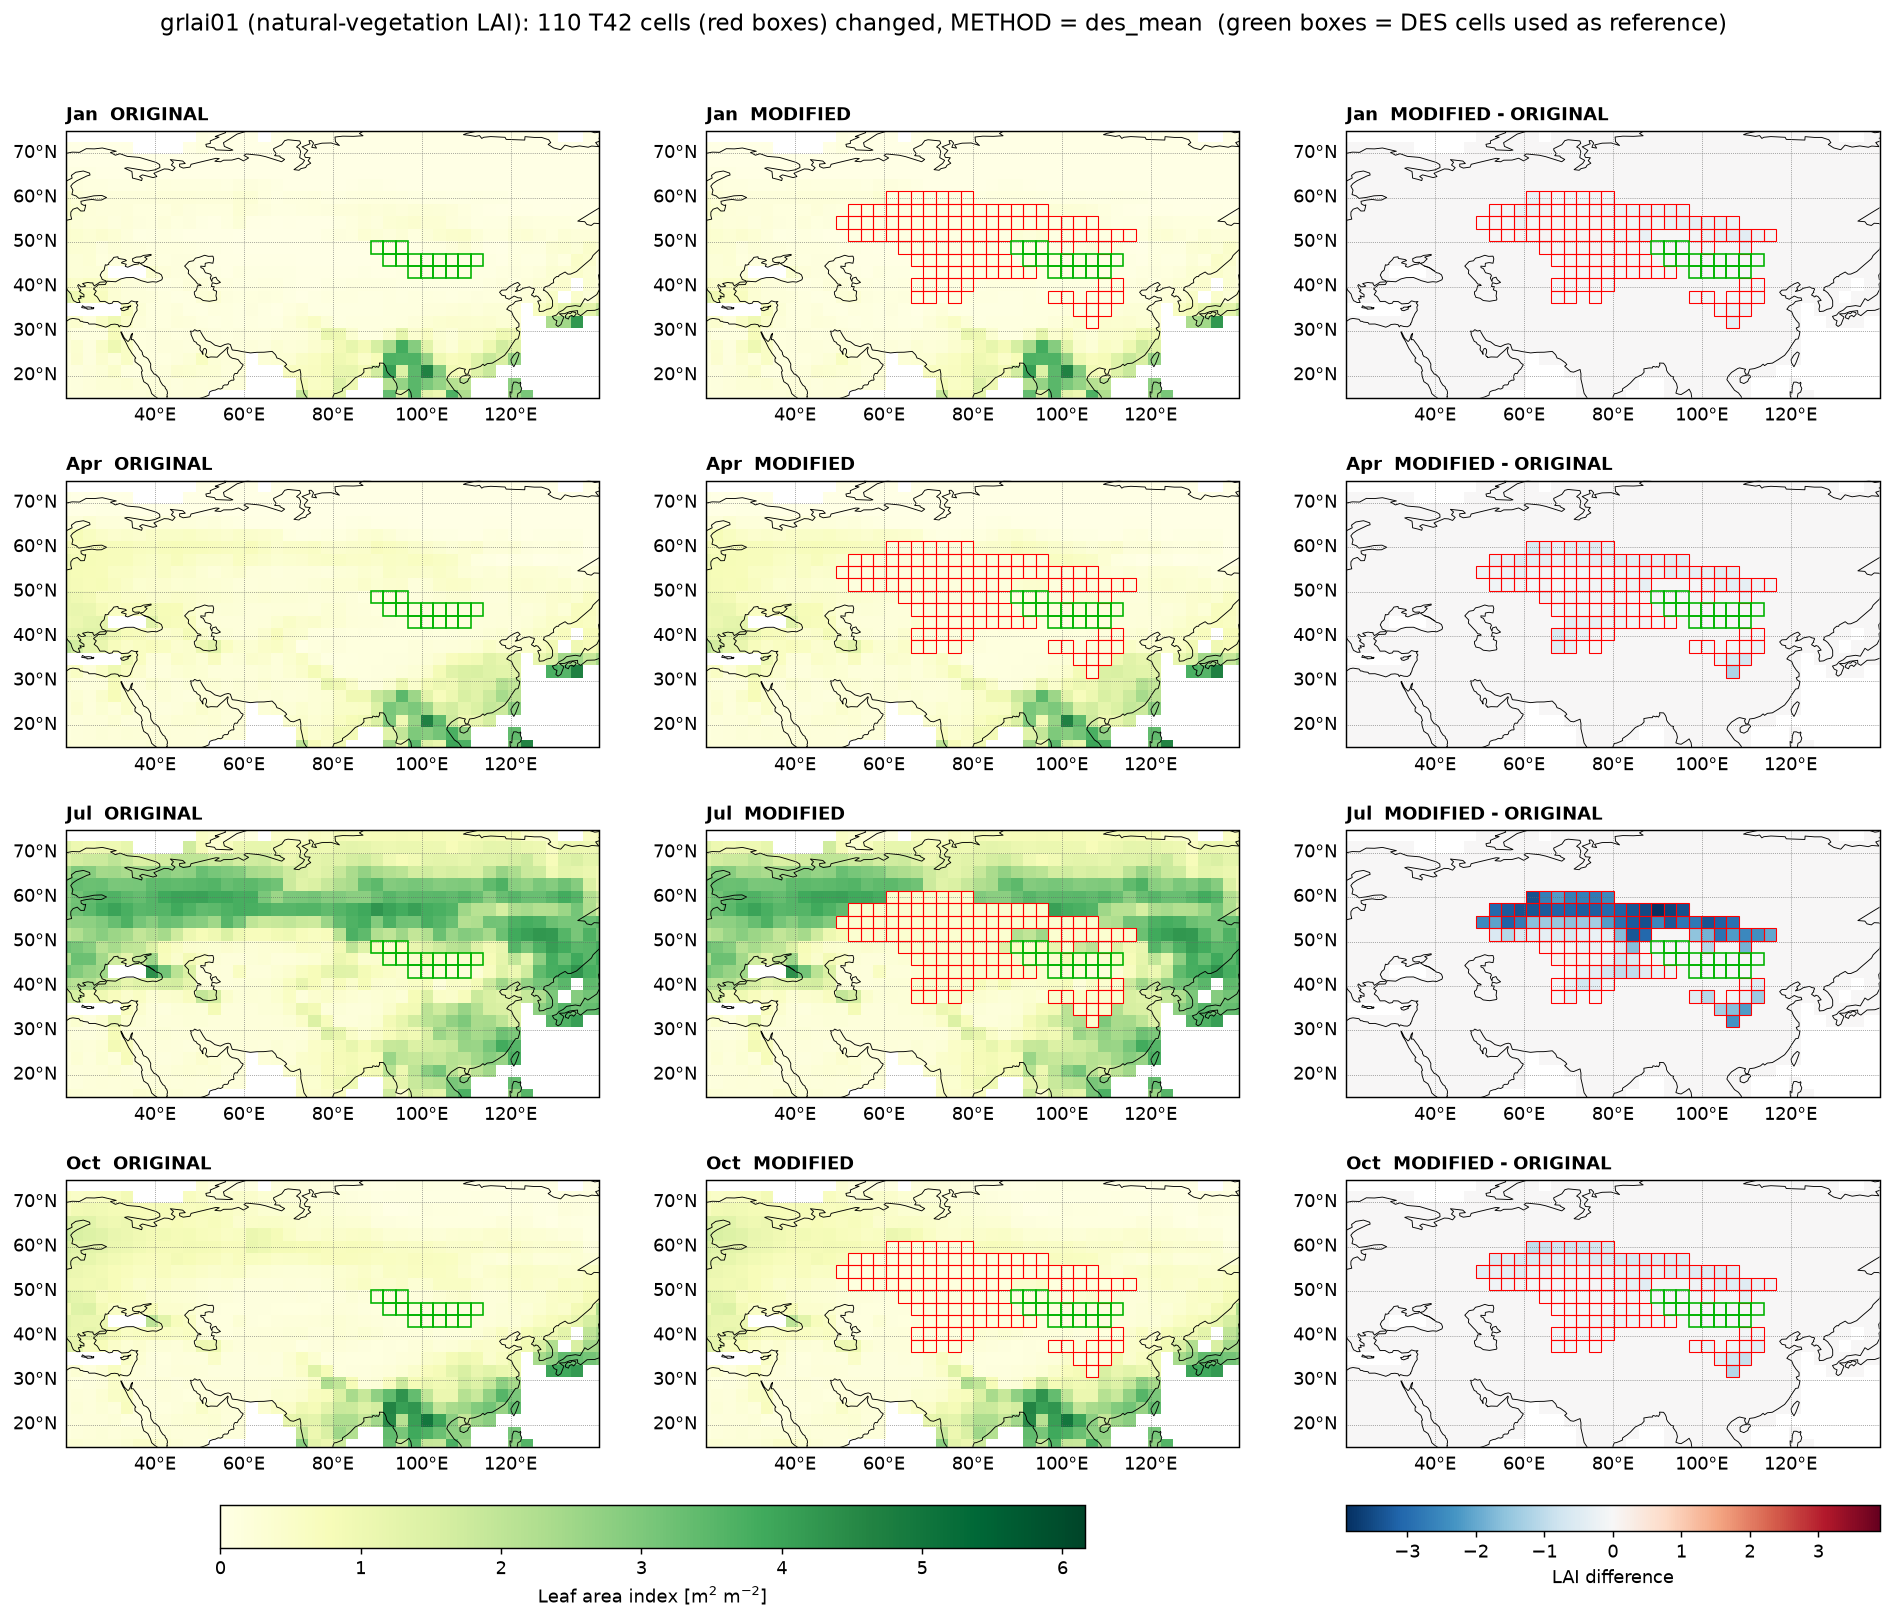

/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/peterchang/opt/anaconda3/envs/Geo

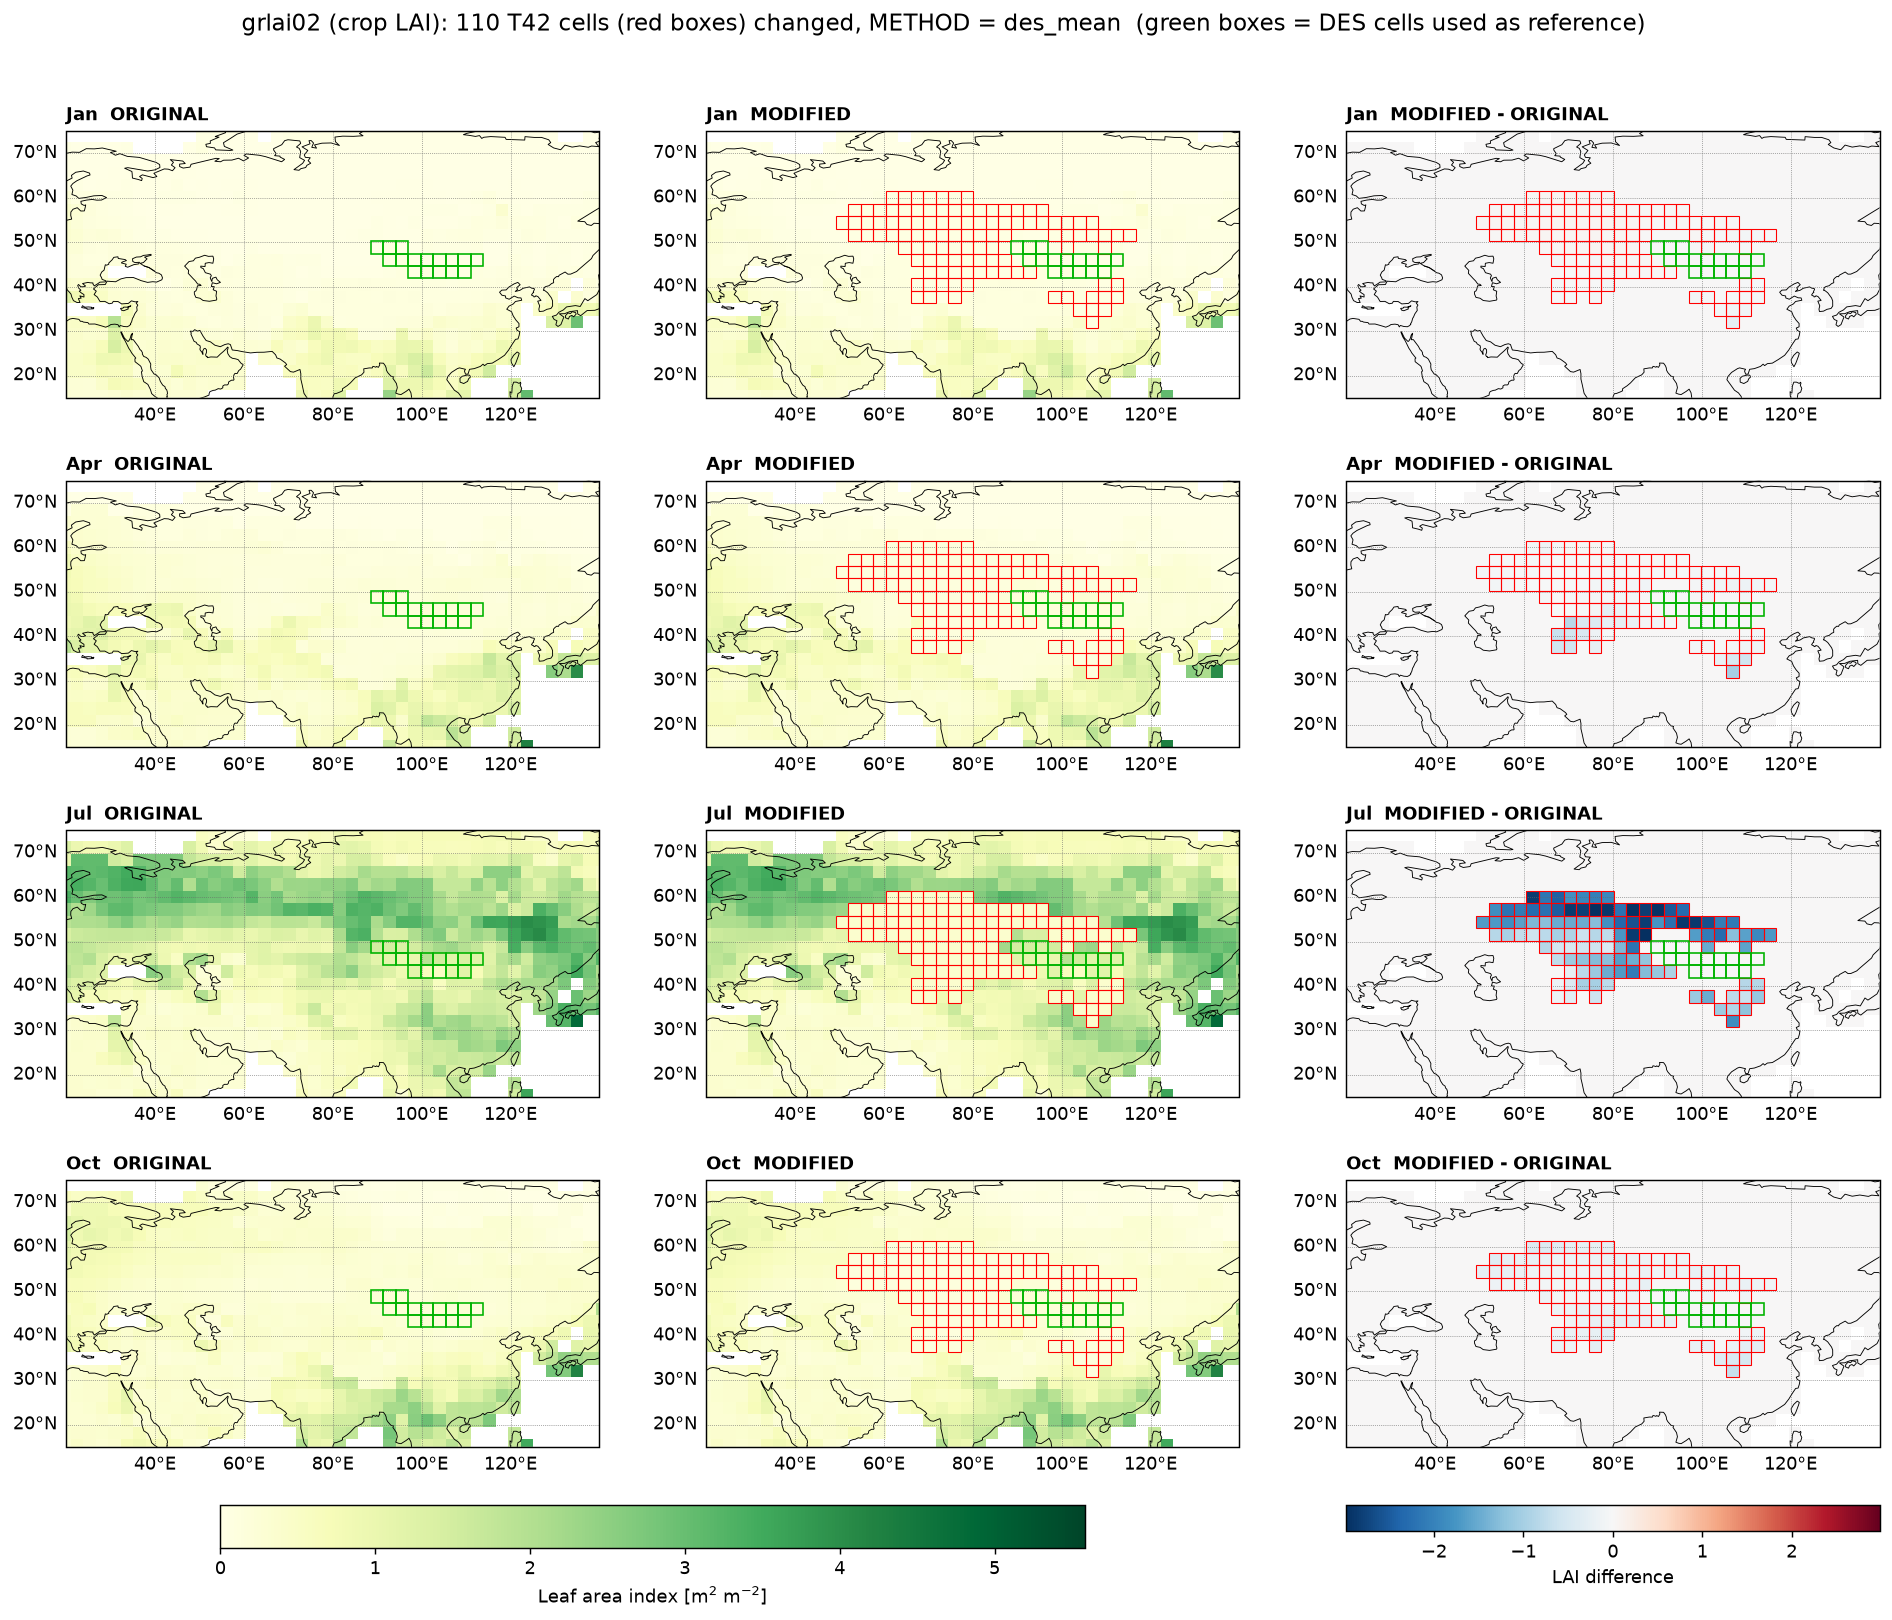

In [6]:
MONTHS = [0, 3, 6, 9]                              # Jan, Apr, Jul, Oct
TITLE = {"grlai01": "natural-vegetation LAI", "grlai02": "crop LAI"}

for v in VARS:
    lai, new = D[v]["lai"], D[v]["new"]
    vmax = float(np.nanmax(lai))
    d = new - lai; dmax = max(float(np.nanmax(np.abs(d[:, sel]))), 0.1)
    fig, axes = plt.subplots(len(MONTHS), 3, figsize=(18, 3.6 * len(MONTHS)), dpi=130, subplot_kw=dict(projection=pc))
    for r, t in enumerate(MONTHS):
        p1 = axes[r, 0].pcolormesh(xe, ye, R(lai[t]), cmap="YlGn", vmin=0, vmax=vmax, transform=pc)
        axes[r, 1].pcolormesh(xe, ye, R(new[t]), cmap="YlGn", vmin=0, vmax=vmax, transform=pc)
        p3 = axes[r, 2].pcolormesh(xe, ye, R(d[t]), cmap="RdBu_r", norm=TwoSlopeNorm(0, -dmax, dmax), transform=pc)
        for c, name in enumerate(["ORIGINAL", "MODIFIED", "MODIFIED - ORIGINAL"]):
            decorate(axes[r, c], f"{mo[t]}  {name}")
            if c: boxes(axes[r, c], sel, "red", 0.6)
            if METHOD == "des_mean": boxes(axes[r, c], ref, "#00b300", 0.9)
    fig.colorbar(p1, ax=axes[:, :2], orientation="horizontal", fraction=0.03, pad=0.04, label="Leaf area index [m$^2$ m$^{-2}$]")
    fig.colorbar(p3, ax=axes[:, 2], orientation="horizontal", fraction=0.03, pad=0.04, label="LAI difference")
    fig.suptitle(f"{v} ({TITLE.get(v, v)}): {int(sel.sum())} T42 cells (red boxes) changed, METHOD = {METHOD}"
                 + ("  (green boxes = DES cells used as reference)" if METHOD == "des_mean" else ""), fontsize=13, y=0.93)
    fig.savefig(FIG / f"{v}_compare.png", bbox_inches="tight")
    print("saved", FIG / f"{v}_compare.png")

## 5 - Figure: LAI seasonal cycle over the 110 cells

saved /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Figure/build_desert_experiment/grlai_seasonal_cycle.png


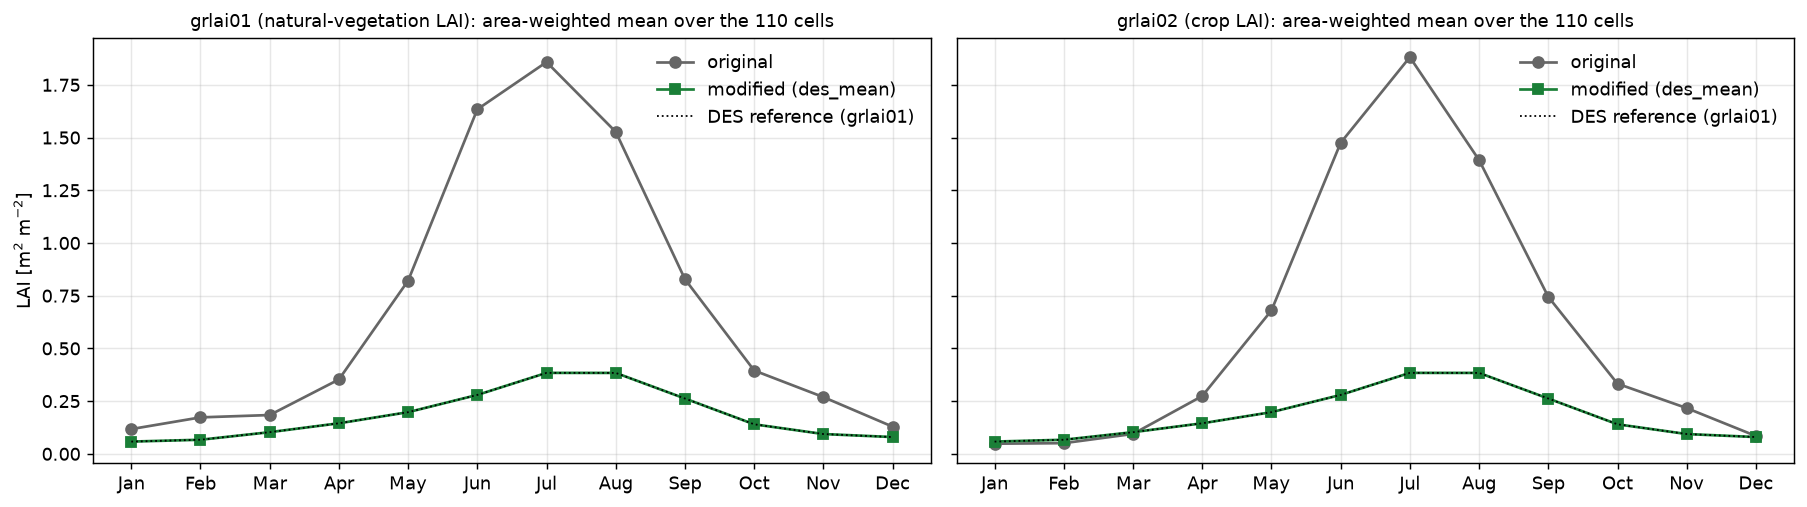

In [7]:
fig, axes = plt.subplots(1, len(VARS), figsize=(7 * len(VARS), 4), dpi=130, sharey=True, squeeze=False)
x = np.arange(1, 13)
for ax, v in zip(axes[0], VARS):
    ax.plot(x, mean(D[v]["lai"]), "o-", color="0.4", label="original")
    ax.plot(x, mean(D[v]["new"]), "s-", color="#1a7f37", label=f"modified ({METHOD})")
    if D[v]["target"] is not None:
        ax.plot(x, D[v]["target"], ":", color="k", lw=1, label=("DES" if METHOD == "des_mean" else "class-5") + f" reference ({REF_FROM.get(v, v)})")
    ax.set_xticks(x, mo); ax.grid(alpha=0.3)
    ax.set_title(f"{v} ({TITLE.get(v, v)}): area-weighted mean over the {int(sel.sum())} cells", fontsize=10)
    ax.legend(frameon=False)
axes[0, 0].set_ylabel("LAI [m$^2$ m$^{-2}$]")
fig.tight_layout(); fig.savefig(FIG / "grlai_seasonal_cycle.png", bbox_inches="tight")
print("saved", FIG / "grlai_seasonal_cycle.png")